cv2.IMREAD_COLOR：以彩色图像的方式读入
cv2.IMREAD_GRAYSCALE：以灰度图像的方式读入

图像的基本操作

In [39]:

import cv2
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline


In [40]:
img=cv2.imread('cat.jpg')

In [41]:
img

array([[[176, 192, 199],
        [176, 192, 199],
        [176, 192, 199],
        ...,
        [169, 184, 193],
        [169, 184, 193],
        [170, 185, 194]],

       [[178, 194, 201],
        [178, 194, 201],
        [178, 194, 201],
        ...,
        [169, 184, 193],
        [170, 185, 194],
        [170, 185, 194]],

       [[180, 196, 203],
        [180, 196, 203],
        [180, 196, 203],
        ...,
        [170, 185, 194],
        [170, 185, 194],
        [170, 185, 194]],

       ...,

       [[227, 230, 228],
        [210, 213, 211],
        [205, 208, 206],
        ...,
        [ 85,  98, 112],
        [ 79,  92, 106],
        [ 80,  93, 107]],

       [[226, 229, 227],
        [208, 211, 209],
        [201, 204, 202],
        ...,
        [ 90, 103, 117],
        [ 85,  98, 112],
        [ 84,  97, 111]],

       [[224, 227, 225],
        [208, 211, 209],
        [203, 206, 204],
        ...,
        [ 94, 107, 121],
        [ 93, 106, 120],
        [ 92, 105, 119]]

In [42]:
cv2.imshow("cat", img)#图像显示
cv2.waitKey(1000)#0表示任意键停止，单位ms，10000表示10秒后自动关闭
cv2.destroyAllWindows()

In [43]:
def cv_show(name,img):
    cv2.imshow(name,img)
    cv2.waitKey(0)
    cv2.destroyAllWindows()
    

In [44]:
img.shape

(148, 254, 3)

In [45]:
img=cv2.imread('cat.jpg',cv2.IMREAD_GRAYSCALE)
img

In [46]:
cv2.imshow("cat", img)#图像显示
cv2.waitKey(1000)  # 等待按键
cv2.destroyAllWindows()  # 关闭所有窗口


error: OpenCV(5.0.0) D:\a\opencv-python\opencv-python\opencv\modules\highgui\src\window.cpp:951: error: (-215:Assertion failed) size.width>0 && size.height>0 in function 'cv::imshow'


In [ ]:
#保存
cv2.imwrite('catgray.jpg',img)

True

In [ ]:
type(img)#底层

numpy.ndarray

In [ ]:
img.size#像素点个数

37592

In [ ]:
img.dtype##数据类型

dtype('uint8')

#数据读取--视频
cv2.VideoCapture可以捕获摄像头，用数字来控制不同的设备，例如0，1
如果是视频文件，直接指定路径即可

In [ ]:
vc = cv2.VideoCapture('test.mp4')#读取视频文件

In [ ]:
#检查是否打开通道
if vc.isOpened():
    open,frame=vc.read()
else:
    open=False

In [ ]:
while open:
    ret,frame=vc.read()
    if frame is None:
        break
    if ret==True:
        gray=cv2.cvtColor(frame,cv2.COLOR_BGR2GRAY)
        cv2.imshow('restult',gray)
        if cv2.waitKey(10) & 0xFF==27:#按下ESC键退出，时间越长，播放速度越慢
            break
vc.release()
cv2.destroyAllWindows()

截取部分图像数据

In [ ]:
img=cv2.imread('cat.jpg')
cat=img[0:200,0:200]#裁剪切片,  0:200表示行的范围，0:200表示列的范围
cv2.imshow('cat',cat)
cv2.waitKey(1000)
cv2.destroyAllWindows()

颜色通道提取

In [ ]:
b,g,r=cv2.split(img)#分离通道

In [ ]:
b

array([[176, 176, 176, ..., 169, 169, 170],
       [178, 178, 178, ..., 169, 170, 170],
       [180, 180, 180, ..., 170, 170, 170],
       ...,
       [227, 210, 205, ...,  85,  79,  80],
       [226, 208, 201, ...,  90,  85,  84],
       [224, 208, 203, ...,  94,  93,  92]], shape=(148, 254), dtype=uint8)

In [ ]:
b.shape

(148, 254)

In [ ]:
img=cv2.merge([b,g,r])#合并通道
img.shape

(148, 254, 3)

In [ ]:
#只保留R
cur_img=img.copy()#复制图像
cur_img[:,:,0]=0#将图像的蓝色通道置为0
cur_img[:,:,1]=0#将图像的绿色通道置为0
cv_show('R',cur_img)


In [ ]:
#只保留G
cur_img=img.copy()#复制图像
cur_img[:,:,0]=0#将图像的蓝色通道置为0
cur_img[:,:,2]=0#将图像的红色通道置为0
cv_show('G',cur_img)

In [ ]:
#只保留B
cur_img=img.copy()#复制图像
cur_img[:,:,1]=0#将图像的绿色通道置为0
cur_img[:,:,2]=0#将图像的红色通道置为0
cv_show('B',cur_img)

边界填充
cv2.copyMakeBorder：给图片扩充边框（padding）
cv2.BORDER_CONSTANT：常量填充模式，边框用固定颜色
value=[0,0,255]：注意OpenCV是BGR顺序
B=0，G=0，R=255 → 红色边框

In [ ]:
top_size,bottom_size,left_size,right_size=50,50,50,50#上下左右各扩充50像素

replicate=cv2.copyMakeBorder(img,top_size,bottom_size,left_size,right_size,cv2.BORDER_REPLICATE)#复制边界
reflect=cv2.copyMakeBorder(img,top_size,bottom_size,left_size,right_size,cv2.BORDER_REFLECT)#镜像反射
reflect101=cv2.copyMakeBorder(img,top_size,bottom_size,left_size,right_size,cv2.BORDER_REFLECT_101)#镜像反射
wrap=cv2.copyMakeBorder(img,top_size,bottom_size,left_size,right_size,cv2.BORDER_WRAP)#环绕
constant=cv2.copyMakeBorder(img,top_size,bottom_size,left_size,right_size,cv2.BORDER_CONSTANT,value=[0,0,255])#常量边界，value表示边界颜色

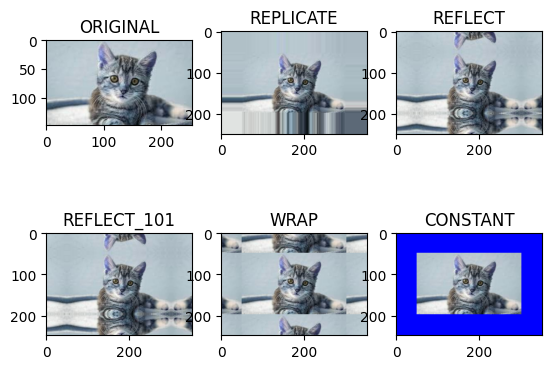

In [ ]:
import matplotlib.pyplot as plt
plt.subplot(231),plt.imshow(img,'gray'),plt.title('ORIGINAL')#subplot(231)：建立2行3列的子图布局，当前是第1个位置，imshow(img,'gray')：以灰度图方式显示img（原图）title('ORIGINAL')：子图标题：原图
plt.subplot(232),plt.imshow(replicate,'gray'),plt.title('REPLICATE')#2行3列，第2张图，灰度显示replicate，标题：REPLICATE（复制填充，边界复制边缘像素）
plt.subplot(233),plt.imshow(reflect,'gray'),plt.title('REFLECT')#2行3列，第3张图，灰度显示reflect，标题：REFLECT（镜像反射，边界镜像反射边缘像素）
plt.subplot(234),plt.imshow(reflect101,'gray'),plt.title('REFLECT_101')#2行3列第4张图，灰度显示reflect101，标题：REFLECT_101（镜像反射，边界镜像反射边缘像素）
plt.subplot(235),plt.imshow(wrap,'gray'),plt.title('WRAP')#2行3列，第5张图，灰度显示wrap，标题：WRAP（环绕填充，边界环绕复制边缘像素）
plt.subplot(236),plt.imshow(constant,'gray'),plt.title('CONSTANT')#2行3列第6张图，灰度显示constant，标题：CONSTANT（常量填充，边界填充指定颜色）
plt.show()

BORDER_REFLICATE：复制法，也就是复制最边缘像素
BORDER_REFLECT：反射法，对感兴趣的图像中的像素在两边进行复制，例如：fedcba|abcdefgh|hgfedcb
BORDER_REFLECT_101：反射法，也就是以最边缘像素为轴，对称，例如：gfedcb、abcdefgh|gfedcba
BORDER_WRAP：对外包装法，例如：cdefgh|abcdefgh|abcdefg
BORDER_CONSTANT：常量法，常数值填充

数值计算

In [48]:
#读取
img_cat=cv2.imread('cat.jpg')
img_dog=cv2.imread('dog.jpg')

In [51]:
img_cat2=img_cat+10#每个像素点加10
img_cat[:5,:,0]

array([[176, 176, 176, ..., 169, 169, 170],
       [178, 178, 178, ..., 169, 170, 170],
       [180, 180, 180, ..., 170, 170, 170],
       [180, 180, 180, ..., 170, 170, 171],
       [178, 178, 178, ..., 171, 171, 171]], shape=(5, 254), dtype=uint8)

In [52]:
img_cat2[:5,:,0]

array([[186, 186, 186, ..., 179, 179, 180],
       [188, 188, 188, ..., 179, 180, 180],
       [190, 190, 190, ..., 180, 180, 180],
       [190, 190, 190, ..., 180, 180, 181],
       [188, 188, 188, ..., 181, 181, 181]], shape=(5, 254), dtype=uint8)

In [53]:
(img_cat+img_cat2)[:5,:,0]#超出部分%255

array([[106, 106, 106, ...,  92,  92,  94],
       [110, 110, 110, ...,  92,  94,  94],
       [114, 114, 114, ...,  94,  94,  94],
       [114, 114, 114, ...,  94,  94,  96],
       [110, 110, 110, ...,  96,  96,  96]], shape=(5, 254), dtype=uint8)

In [54]:
cv2.add(img_cat,img_cat2)[:5,:,0]#此函数：未越界取自身，越界取255

array([[255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255]], shape=(5, 254), dtype=uint8)

图像融合

In [55]:
#img_cat+img_dog   shape值不相同无法
img_cat.shape

(148, 254, 3)

In [ ]:
img_dog=cv2.resize(img_dog,(254,148))
img_dog.shape

(148, 254, 3)

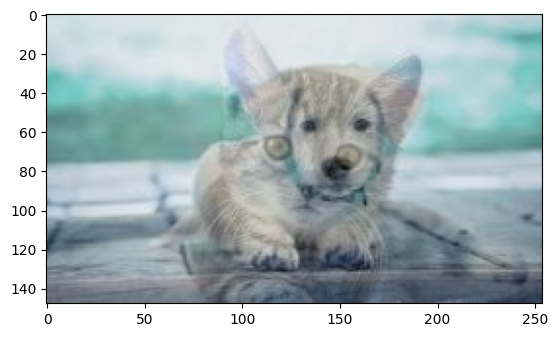

In [ ]:
#类似于y=ax1+bx2，a表示图像1的权重，b表示图像2的权重
res=cv2.addWeighted(img_cat,0.4,img_dog,0.6,0)
plt.imshow(res)

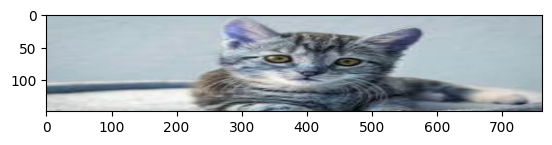

In [ ]:
#(0,0)不指定距离，fx=3表示x轴乘以3，fy=1表示y轴乘以1，表示倍数
res=cv2.resize(img,(0,0),fx=3,fy=1)
plt.imshow(res)
